
## Idiosyncratic volatility factor: Low-minus-High portfolios (2005-2025)

**Question.** Do stocks with low idiosyncratic volatility earn higher risk-adjusted returns than stocks with high idiosyncratic volatility? This is the low-volatility anomaly (Ang, Hodrick, Xing and Zhang, 2006). Standard risk-return theory predicts the opposite sign, so a positive factor premium points to behavioral or constraint-based explanations rather than compensation for risk.

**Idiosyncratic volatility.** For each stock and month-end, regress the trailing 60 months of stock excess returns on market excess returns. The idiosyncratic volatility is the standard deviation of the residuals (residual sum of squares divided by n - 2). It removes each stock's own market-driven variation, but across stocks it is still positively correlated with ordinary beta (high-beta stocks tend to have high idiosyncratic volatility), so the summary table reports each quintile's average beta and the CAPM regression adjusts LMH for the resulting market exposure. Estimates need a full 60-calendar-month window and at least 36 valid paired observations. Raw supplied monthly `total_return` is used (not the winsorized series).

**Factor.** Each return month t, stocks are ranked into five equal-count quintiles on idiosyncratic volatility estimated through month t-1 (no look-ahead). Q1 is lowest volatility and Q5 is highest. Portfolios are equal-weighted (the data has no market capitalization). The factor is **LMH = Q1 - Q5**, so a positive premium is the expected sign. The risk-free rate cancels in the spread.

**Tests.**

1. Time-series CAPM regression of LMH on the market excess return (and of each quintile portfolio), testing whether the alpha is zero:

\[
R^e_{p,t}=\alpha_p+\beta_p\,(R_{m,t}-R_{f,t})+\varepsilon_{p,t}
\]

2. Separate two-factor regressions of each individual stock's excess return on the market and LMH, with tests of the alpha, market beta and LMH beta. Report the number and percentage of stocks whose betas are significant.

Standard errors are Newey-West/HAC with six lags, p-values are two-sided with a normal approximation, and confidence intervals are 95%. Return months run from January 2005 (the first month with a full 60-month window) through the end of the data. Limitations: the stock file has no delisting returns, may have survivorship bias, and has no market capitalization, so value-weighted portfolios and size/value controls are not possible.

**How to read the outputs.** The cleaning log reports rows remaining and rows affected at each data check; the outlier row is a diagnostic count and those raw observations remain in the primary analysis. The rolling-estimate counts show how many stock-month beta and idiosyncratic-volatility estimates meet the window and observation requirements. In the current input data, the cleaning table records 156,560 source rows, no duplicate rows removed, five missing stock returns removed, and 3,394 returns outside the monthly 1st/99th-percentile diagnostic cutoffs. Those extreme returns are retained in the raw analysis.

In [52]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WINDOW_MONTHS = 60
MIN_OBSERVATIONS = 36
HAC_LAGS = 6
N_QUINTILES = 5
MIN_STOCKS_PER_QUINTILE = 10
SAMPLE_START = pd.Timestamp("2005-01-31")
WINSOR_LOWER, WINSOR_UPPER = 0.01, 0.99

data_dir = Path.cwd()
if not (data_dir / "market_returns_2000_2025.csv").is_file():
    data_dir = data_dir / "CAPM Factors"

# Market and risk-free series.
market = pd.read_csv(data_dir / "market_returns_2000_2025.csv", parse_dates=["date"])
risk_free = pd.read_csv(data_dir / "risk_free_rate_2000_2025.csv", parse_dates=["date"])
monthly = market.merge(risk_free, on="date", how="outer", validate="one_to_one", indicator=True)
unmatched = monthly.loc[monthly["_merge"] != "both", "date"]
if not unmatched.empty:
    raise ValueError(f"Market and risk-free CSV dates do not match: {unmatched.tolist()[:5]}")
if monthly[["market_return", "rf_1m"]].isna().any().any():
    raise ValueError("Market return or risk-free rate contains missing values.")
factors = pd.DataFrame(
    {
        "Mkt-RF": (monthly["market_return"] - monthly["rf_1m"]).to_numpy(),
        "RF": monthly["rf_1m"].to_numpy(),
    },
    index=pd.DatetimeIndex(monthly["date"], name="date"),
).sort_index()
calendar = factors.index
expected_calendar = pd.date_range(calendar.min(), calendar.max(), freq=pd.offsets.MonthEnd())
if not calendar.equals(expected_calendar):
    raise ValueError("Market data must contain one continuous observation per month-end.")

# Stock returns: validate and clean, logging how many observations each step affects.
stocks = pd.read_csv(data_dir / "sp500_stocks_2000_2025.csv", parse_dates=["date"])
required_columns = {"date", "permno", "ticker", "company_name", "total_return"}
missing_columns = required_columns.difference(stocks.columns)
if missing_columns:
    raise ValueError(f"Stock data is missing required columns: {sorted(missing_columns)}")
if stocks["date"].isna().any() or stocks["permno"].isna().any():
    raise ValueError("Stock data contains missing or invalid dates or PERMNO identifiers.")
if not stocks["date"].dt.is_month_end.all():
    raise ValueError("Expected month-end observations in the stock return file.")
stocks["total_return"] = pd.to_numeric(stocks["total_return"], errors="raise")
if not stocks["date"].isin(calendar).all():
    raise ValueError("Stock-return dates do not all align with market months.")

cleaning_log = [("Source rows", len(stocks), 0)]
key_columns = ["permno", "date"]
duplicate_rows = stocks.duplicated(key_columns, keep=False)
if duplicate_rows.any():
    conflicting = stocks.loc[duplicate_rows].groupby(key_columns).nunique(dropna=False).gt(1).any(axis=1)
    if conflicting.any():
        raise ValueError("Conflicting duplicate PERMNO/date observations found.")
n_duplicates = int(stocks.duplicated(key_columns).sum())
stocks = stocks.drop_duplicates(key_columns)
cleaning_log.append(("Exact duplicate PERMNO/date rows removed", len(stocks), n_duplicates))

n_missing = int(stocks["total_return"].isna().sum())
stocks = stocks.dropna(subset=["total_return"])
cleaning_log.append(("Missing total_return rows removed", len(stocks), n_missing))

lower, upper = stocks.groupby("date")["total_return"].transform(
    lambda r: r.quantile(WINSOR_LOWER)), stocks.groupby("date")["total_return"].transform(
    lambda r: r.quantile(WINSOR_UPPER))
n_extreme = int((~stocks["total_return"].between(lower, upper)).sum())
cleaning_log.append(
    (f"Returns outside monthly {WINSOR_LOWER:.0%}/{WINSOR_UPPER:.0%} cut-offs (informational; raw returns are used)",
     len(stocks), n_extreme)
)
cleaning_log = pd.DataFrame(cleaning_log, columns=["step", "rows_remaining", "rows_affected"])

# Wide month x PERMNO panel of raw total returns on the full market calendar.
returns_wide = stocks.pivot(index="date", columns="permno", values="total_return").reindex(calendar)
display(cleaning_log)
print(f"Stocks: {returns_wide.shape[1]}; months: {returns_wide.shape[0]} "
      f"({calendar.min():%Y-%m} through {calendar.max():%Y-%m})")


,step,rows_remaining,rows_affected
0,Source rows,156560,0
1,Exact duplicate PERMNO/date rows removed,156560,0
2,Missing total_return rows removed,156555,5
3,Returns outside monthly 1%/99% cut-offs (infor...,156555,3394


Stocks: 1081; months: 312 (2000-01 through 2025-12)


## Rolling 60-month beta and idiosyncratic volatility

For each stock and month-end, the trailing 60-month CAPM regression of stock excess returns on market excess returns gives the ordinary beta and the residual (idiosyncratic) volatility. Both are computed from rolling sums over paired observations, require a full 60-calendar-month window and at least 36 valid observations, and are NaN if the market variance is zero. The estimate dated t is available after month t closes and is used for the next return month.

The two printed diagnostics are coverage counts, not performance results: the first is the number of PERMNO-month estimates with sufficient usable history; the second identifies when rolling estimates first become available. The estimates are characteristics used to sort portfolios in the following return month.

In [53]:
stock_excess = returns_wide.sub(factors["RF"], axis=0)
market_excess = factors["Mkt-RF"]
valid = stock_excess.notna()

s = stock_excess.where(valid, 0.0)            # stock excess return, zero where missing
m = valid.mul(market_excess, axis=0)          # paired market excess return, zero where missing


def rolling_sum(frame):
    return frame.rolling(WINDOW_MONTHS, min_periods=1).sum()


n_obs = rolling_sum(valid.astype(float))
sum_s, sum_m = rolling_sum(s), rolling_sum(m)
sum_sm, sum_mm, sum_ss = rolling_sum(s * m), rolling_sum(m ** 2), rolling_sum(s ** 2)

with np.errstate(divide="ignore", invalid="ignore"):
    cov_sm = sum_sm - sum_s * sum_m / n_obs
    var_m = sum_mm - sum_m ** 2 / n_obs
    var_s = sum_ss - sum_s ** 2 / n_obs
    beta_all = cov_sm / var_m
    residual_ss = var_s - cov_sm ** 2 / var_m
    idio_vol_all = np.sqrt((residual_ss / (n_obs - 2)).clip(lower=0))

usable = (n_obs >= MIN_OBSERVATIONS) & (var_m > 0)
usable.iloc[: WINDOW_MONTHS - 1] = False       # require a full 60-calendar-month window
beta_est = beta_all.where(usable)
idio_vol_est = idio_vol_all.where(usable)
print(f"Stock-month estimates available: {int(usable.to_numpy().sum()):,}")
print(f"First estimation month: {idio_vol_est.dropna(how='all').index.min():%Y-%m}")


Stock-month estimates available: 121,399
First estimation month: 2004-12


## Low-minus-High idiosyncratic volatility portfolios and CAPM alpha

Quintiles are formed each month on idiosyncratic volatility estimated through the prior month. Q1 holds the lowest-volatility stocks and Q5 the highest. LMH is Q1 minus Q5.

**Figures and tables in this section.** Figure 1 compares each portfolio's CAPM alpha and market beta; bars are estimates and whiskers are 95% HAC confidence intervals, so intervals crossing zero indicate estimates not distinguishable from zero at the 5% level. Figure 2 plots monthly LMH returns against market excess returns; the fitted line's intercept is alpha and its slope is market beta. Figure 3 shows compounded growth of a notional dollar in each portfolio's monthly excess returns; it is a historical path, not a risk-adjusted performance measure. The portfolio summary table reports mean and volatility of monthly excess returns, average number of stocks, and average lagged sorting volatility and market beta. The CAPM table reports alpha and market beta, HAC errors, confidence intervals, p-values, R-squared, and sample months; alpha tests risk-adjusted performance while beta describes market exposure.

**What the current results show.** In Figure 1, portfolio market beta rises from Q1 to Q5, while the LMH beta is negative; the LMH alpha confidence interval crosses zero. Figure 2's downward fitted line reflects the negative LMH market beta, meaning the spread tends to move opposite the market. The portfolio table shows Q5 has the highest average market sensitivity and higher volatility than Q1, while the raw LMH mean return is negative. In Figure 3, Q1's cumulative excess-return path finishes above Q5 in this sample, but neither that path nor a visual gap establishes a statistically reliable premium; use the CAPM alpha and its interval for risk-adjusted inference.

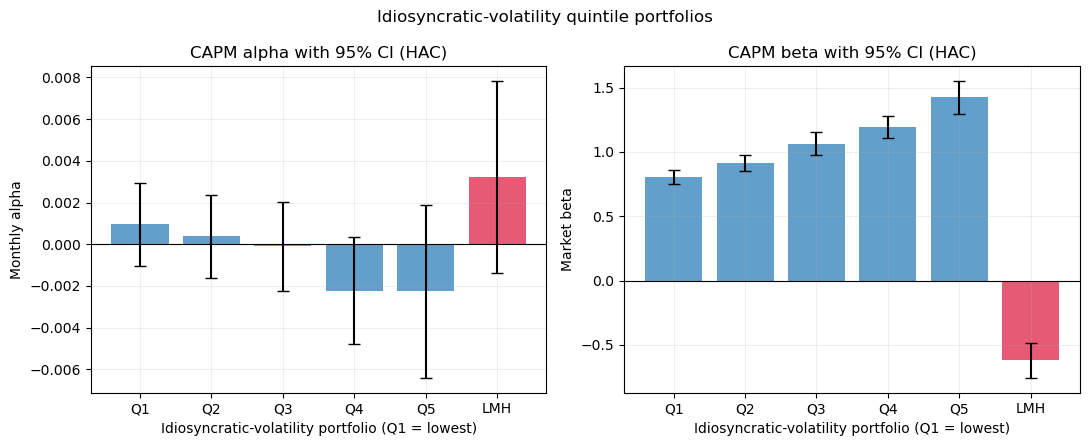

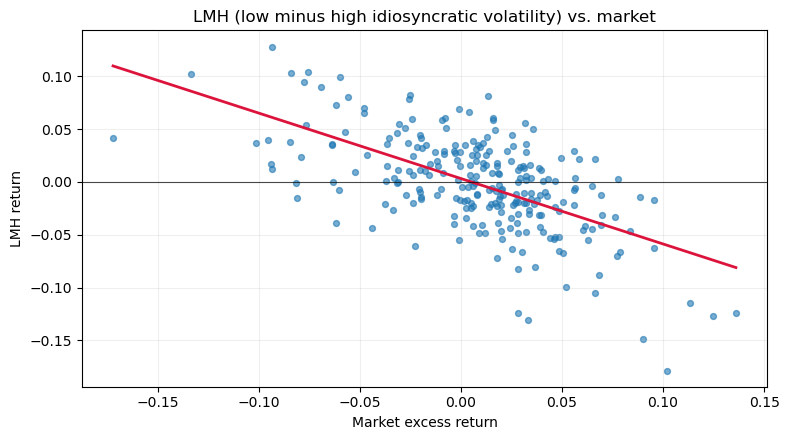

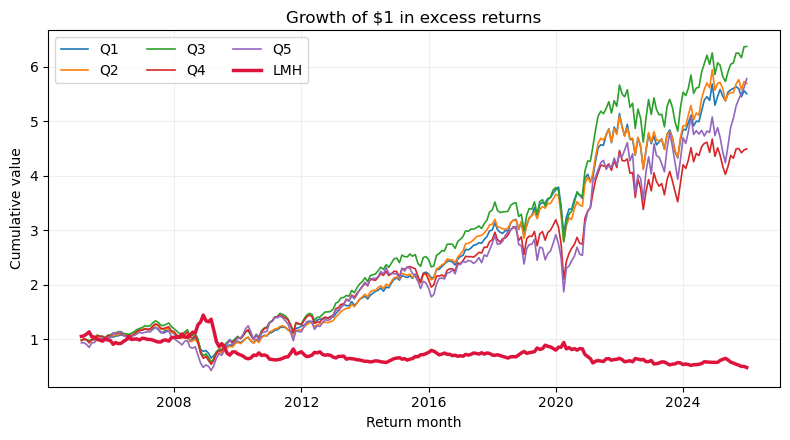

Portfolio months (inclusive): 2005-01 through 2025-12 (252 months)
Quintiles are formed each month on idiosyncratic volatility estimated through the prior month; equal-weighted; LMH = Q1 - Q5.
Inference: Newey-West/HAC standard errors (6 lags); p-values use the normal approximation.


,mean_excess_return,std_dev,mean_stocks_per_month,avg_idio_vol,avg_beta
portfolio,,,,,
Q1,0.007550,0.038725,93.769841,0.042490,0.768495
Q2,0.007870,0.043238,92.289683,0.053458,0.863387
Q3,0.008622,0.049710,89.071429,0.063470,1.022582
Q4,0.007574,0.056228,86.932540,0.077626,1.181781
Q5,0.009414,0.069804,76.170635,0.115091,1.593440
LMH,-0.001864,0.045466,NaN,NaN,NaN


,portfolio,term,estimate,annualized_estimate,hac_std_error,t_stat,p_value_normal_approx,ci_95_low,ci_95_high,r_squared,n_months
0,Q1,alpha,0.000959,0.011512,0.001010,0.950081,3.420711e-01,-0.001020,0.002938,0.843256,252
1,Q1,beta,0.804541,NaN,0.026694,30.139932,1.453445e-199,0.752221,0.856860,0.843256,252
2,Q2,alpha,0.000382,0.004580,0.001009,0.378356,7.051659e-01,-0.001596,0.002359,0.873160,252
3,Q2,beta,0.914095,NaN,0.032510,28.117332,6.014605e-174,0.850376,0.977815,0.873160,252
4,Q3,alpha,-0.000093,-0.001121,0.001092,-0.085558,9.318179e-01,-0.002234,0.002047,0.895026,252
5,Q3,beta,1.063991,NaN,0.046688,22.789155,5.873780e-115,0.972482,1.155500,0.895026,252
6,Q4,alpha,-0.002220,-0.026642,0.001301,-1.706738,8.787069e-02,-0.004770,0.000329,0.883365,252
7,Q4,beta,1.195629,NaN,0.043883,27.245779,1.864701e-163,1.109618,1.281640,0.883365,252
8,Q5,alpha,-0.002253,-0.027034,0.002119,-1.062932,2.878129e-01,-0.006407,0.001901,0.813288,252
9,Q5,beta,1.424224,NaN,0.064131,22.208015,2.873556e-109,1.298527,1.549921,0.813288,252


LMH alpha: estimate=0.003212, 95% CI=(-0.001397, 0.007821), p=0.1719; not statistically significant at 5%.
LMH beta: estimate=-0.619683, 95% CI=(-0.756545, -0.482822), p=0.0000; statistically significant at 5%.


In [54]:
# Characteristics lagged one month: estimated through t-1, used for return month t.
lag_vol = idio_vol_est.shift(1)
lag_beta = beta_est.shift(1)

sample_months = calendar[calendar >= SAMPLE_START]
n_ranked = lag_vol.notna().sum(axis=1)
rank = lag_vol.rank(axis=1, method="first")
quintile = ((rank - 1).mul(N_QUINTILES).floordiv(n_ranked, axis=0) + 1)
quintile = quintile.where(n_ranked.ge(N_QUINTILES * MIN_STOCKS_PER_QUINTILE), np.nan)
quintile.loc[~quintile.index.isin(sample_months)] = np.nan

quintile_returns = pd.DataFrame({
    f"Q{q}": stock_excess.where(quintile.eq(q)).mean(axis=1) for q in range(1, N_QUINTILES + 1)
}).dropna(how="any")
quintile_returns["LMH"] = quintile_returns["Q1"] - quintile_returns[f"Q{N_QUINTILES}"]
mkt_excess = market_excess.reindex(quintile_returns.index)


def newey_west_variance(scores, lags=HAC_LAGS):
    """Bartlett-weighted long-run covariance of the columns of `scores` (T x k)."""
    meat = scores.T @ scores
    for lag in range(1, min(lags, len(scores) - 1) + 1):
        gamma = scores[lag:].T @ scores[:-lag]
        meat += (1 - lag / (lags + 1)) * (gamma + gamma.T)
    return meat


def capm_regression(y, x):
    """OLS of y on [1, x] with Newey-West (Bartlett) standard errors."""
    y = np.asarray(y, dtype=float)
    design = np.column_stack([np.ones(len(y)), np.asarray(x, dtype=float)])
    coefficients = np.linalg.solve(design.T @ design, design.T @ y)
    residuals = y - design @ coefficients
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ newey_west_variance(design * residuals[:, None]) @ bread
    r_squared = 1 - residuals @ residuals / np.sum((y - y.mean()) ** 2)
    return coefficients, np.sqrt(np.diag(covariance)), r_squared, len(y)


portfolio_rows, portfolio_fits = [], {}
for portfolio in quintile_returns.columns:
    coefficients, std_errors, r_squared, n_months = capm_regression(quintile_returns[portfolio], mkt_excess)
    portfolio_fits[portfolio] = coefficients
    for term, estimate, std_error in zip(["alpha", "beta"], coefficients, std_errors):
        t_stat = estimate / std_error
        portfolio_rows.append({
            "portfolio": portfolio,
            "term": term,
            "estimate": estimate,
            "annualized_estimate": estimate * 12 if term == "alpha" else np.nan,
            "hac_std_error": std_error,
            "t_stat": t_stat,
            "p_value_normal_approx": math.erfc(abs(t_stat) / math.sqrt(2)),
            "ci_95_low": estimate - 1.96 * std_error,
            "ci_95_high": estimate + 1.96 * std_error,
            "r_squared": r_squared,
            "n_months": n_months,
        })
vol_capm = pd.DataFrame(portfolio_rows)

# Characteristics of the stocks in each quintile (the sort should leave ordinary beta similar).
in_sample = quintile.index.isin(quintile_returns.index)
summary = pd.DataFrame({
    "mean_excess_return": quintile_returns.mean(),
    "std_dev": quintile_returns.std(),
}).rename_axis("portfolio")
stats_by_quintile = {
    "mean_stocks_per_month": lambda q: (quintile.eq(q) & stock_excess.notna()).loc[in_sample].sum(axis=1).mean(),
    "avg_idio_vol": lambda q: np.nanmean(lag_vol.where(quintile.eq(q)).loc[in_sample].to_numpy()),
    "avg_beta": lambda q: np.nanmean(lag_beta.where(quintile.eq(q)).loc[in_sample].to_numpy()),
}
for column, function in stats_by_quintile.items():
    summary[column] = [function(int(p[1])) if p != "LMH" else np.nan for p in summary.index]

# Figure 1: alpha and beta with 95% confidence intervals for every portfolio.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, term in zip(axes, ["alpha", "beta"]):
    rows = vol_capm.loc[vol_capm["term"].eq(term)].set_index("portfolio")
    error = np.vstack([rows["estimate"] - rows["ci_95_low"], rows["ci_95_high"] - rows["estimate"]])
    colors = ["crimson" if p == "LMH" else "tab:blue" for p in rows.index]
    ax.bar(rows.index, rows["estimate"], color=colors, alpha=0.7)
    ax.errorbar(rows.index, rows["estimate"], yerr=error, fmt="none", ecolor="black", capsize=4)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"CAPM {term} with 95% CI (HAC)", xlabel="Idiosyncratic-volatility portfolio (Q1 = lowest)",
           ylabel="Monthly alpha" if term == "alpha" else "Market beta")
    ax.grid(alpha=0.2)
fig.suptitle("Idiosyncratic-volatility quintile portfolios")
fig.tight_layout()
display(fig)
plt.close(fig)

# Figure 2: LMH spread against the market, with the fitted CAPM line.
alpha_hat, beta_hat = portfolio_fits["LMH"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(mkt_excess, quintile_returns["LMH"], alpha=0.6, s=18)
x_line = np.linspace(mkt_excess.min(), mkt_excess.max(), 100)
ax.plot(x_line, alpha_hat + beta_hat * x_line, color="crimson", linewidth=2)
ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
ax.set(title="LMH (low minus high idiosyncratic volatility) vs. market",
       xlabel="Market excess return", ylabel="LMH return")
ax.grid(alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

# Figure 3: cumulative growth of each quintile's excess return and the spread.
fig, ax = plt.subplots(figsize=(8, 4.5))
growth = (1 + quintile_returns).cumprod()
for portfolio in growth.columns:
    ax.plot(growth.index, growth[portfolio], label=portfolio,
            linewidth=2.5 if portfolio == "LMH" else 1.2,
            color="crimson" if portfolio == "LMH" else None)
ax.set(title="Growth of $1 in excess returns", xlabel="Return month", ylabel="Cumulative value")
ax.legend(ncol=3)
ax.grid(alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

print(f"Portfolio months (inclusive): {quintile_returns.index.min():%Y-%m} through {quintile_returns.index.max():%Y-%m} "
      f"({len(quintile_returns)} months)")
print("Quintiles are formed each month on idiosyncratic volatility estimated through the prior month; equal-weighted; LMH = Q1 - Q5.")
print(f"Inference: Newey-West/HAC standard errors ({HAC_LAGS} lags); p-values use the normal approximation.")
display(summary, vol_capm)

for term in ["alpha", "beta"]:
    result = vol_capm.loc[vol_capm["portfolio"].eq("LMH") & vol_capm["term"].eq(term)].iloc[0]
    significance = (
        "statistically significant at 5%"
        if result["p_value_normal_approx"] < 0.05
        else "not statistically significant at 5%"
    )
    print(
        f"LMH {term}: estimate={result['estimate']:.6f}, "
        f"95% CI=({result['ci_95_low']:.6f}, {result['ci_95_high']:.6f}), "
        f"p={result['p_value_normal_approx']:.4f}; {significance}."
    )


## Individual-stock two-factor regressions: market and LMH

Each stock's monthly excess returns are regressed separately on the market excess return (MKT) and the low-minus-high idiosyncratic-volatility factor (LMH = Q1 - Q5):

\[R^e_{i,t}=\alpha_i+b_i\,\text{MKT}_t+s_i\,\text{LMH}_t+\varepsilon_{i,t}\]

The dependent variables are individual stock returns, not quintile portfolio returns. LMH continues to be formed from equal-weighted volatility quintiles, using the prior month's idiosyncratic-volatility estimates. Each stock regression uses its months with nonmissing stock returns and both factors, and requires at least 36 observations.

**Tests.** For each stock, test whether its market beta (b) and volatility-factor beta (s) differ from zero using Newey-West/HAC standard errors (six lags), two-sided normal-approximation p-values and 95% confidence intervals. The summary reports the number and percentage of eligible stocks with significant betas, separately for MKT and LMH, and splits significant estimates by sign.

**Interpretation caveat.** Significance counts are descriptive and are not adjusted for multiple testing. LMH is built from portfolios in the same stock universe, so its loadings should not be interpreted as an independent out-of-sample test.

**How to read the regression tables.** The significance summary gives the eligible-stock denominator, number and percentage with a coefficient p-value below 0.05, average/median beta, and counts of significant positive and negative betas. The detailed coefficient table has one row per stock and coefficient (intercept, MKT, LMH); use its confidence interval and p-value to assess an individual loading, and its R-squared to assess that stock's in-sample fit. A high percentage of significant MKT loadings is expected for stock returns and does not by itself validate LMH as a priced factor. In this sample, MKT is significant for 738 of 785 eligible stocks (94.0%), all with positive estimates; LMH is significant for 300 of 785 (38.2%), with 124 positive and 176 negative estimates. These per-stock tests are unadjusted for the many stocks tested.

In [55]:
def ols_hac(y, regressors):
    """OLS of y on [1, regressors] with Newey-West standard errors."""
    y = np.asarray(y, dtype=float)
    design = np.column_stack([np.ones(len(y)), np.asarray(regressors, dtype=float)])
    coefficients = np.linalg.solve(design.T @ design, design.T @ y)
    residuals = y - design @ coefficients
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ newey_west_variance(design * residuals[:, None]) @ bread
    r_squared = 1 - residuals @ residuals / np.sum((y - y.mean()) ** 2)
    adj_r_squared = 1 - (1 - r_squared) * (len(y) - 1) / (len(y) - design.shape[1])
    return coefficients, np.sqrt(np.diag(covariance)), r_squared, adj_r_squared


regressor_names = ["MKT", "LMH"]
model_factors = pd.DataFrame({"MKT": mkt_excess, "LMH": quintile_returns["LMH"]})
stock_regression_rows = []

for permno, stock_returns in stock_excess.loc[model_factors.index].items():
    sample = pd.concat(
        [stock_returns.rename("stock_excess"), model_factors], axis=1
    ).dropna()
    n_months = len(sample)
    if n_months < MIN_OBSERVATIONS:
        continue

    regressors = sample[regressor_names].to_numpy(dtype=float)
    design = np.column_stack([np.ones(n_months), regressors])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue

    coefficients, std_errors, r_squared, adj_r_squared = ols_hac(
        sample["stock_excess"], regressors
    )
    for term, estimate, std_error in zip(
        ["alpha", *regressor_names], coefficients, std_errors
    ):
        t_stat = estimate / std_error if std_error > 0 else np.nan
        p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
        stock_regression_rows.append({
            "permno": permno,
            "term": term,
            "estimate": estimate,
            "hac_std_error": std_error,
            "t_stat": t_stat,
            "p_value_normal_approx": p_value,
            "ci_95_low": estimate - 1.96 * std_error,
            "ci_95_high": estimate + 1.96 * std_error,
            "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
            "r_squared": r_squared,
            "adjusted_r_squared": adj_r_squared,
            "n_months": n_months,
        })

stock_regressions = pd.DataFrame(stock_regression_rows)
if stock_regressions.empty:
    raise ValueError("No individual-stock regressions met the sample and rank requirements.")

beta_results = stock_regressions.loc[stock_regressions["term"].isin(regressor_names)]
beta_significance_summary = (
    beta_results.groupby("term", as_index=False)
    .agg(
        eligible_stocks=("permno", "nunique"),
        significant_stocks_5pct=("significant_5pct", "sum"),
        mean_beta=("estimate", "mean"),
        median_beta=("estimate", "median"),
    )
)
beta_significance_summary["significant_percent"] = (
    100 * beta_significance_summary["significant_stocks_5pct"]
    / beta_significance_summary["eligible_stocks"]
)
positive = beta_results.loc[
    beta_results["significant_5pct"] & beta_results["estimate"].gt(0)
].groupby("term")["permno"].nunique()
negative = beta_results.loc[
    beta_results["significant_5pct"] & beta_results["estimate"].lt(0)
].groupby("term")["permno"].nunique()
beta_significance_summary["significant_positive"] = (
    beta_significance_summary["term"].map(positive).fillna(0).astype(int)
)
beta_significance_summary["significant_negative"] = (
    beta_significance_summary["term"].map(negative).fillna(0).astype(int)
)

print(
    f"Individual-stock regressions: excess return = alpha + b*MKT + s*LMH; "
    f"{model_factors.index.min():%Y-%m} through {model_factors.index.max():%Y-%m}."
)
print(
    f"Inference: Newey-West/HAC standard errors ({HAC_LAGS} lags); "
    "two-sided normal-approximation p-values; 5% significance level."
)
print("Percent of eligible stocks with significant market and volatility-factor betas:")
display(beta_significance_summary)
print("Individual-stock coefficient estimates, including confidence intervals:")
display(stock_regressions)
print(
    "LMH is formed from volatility-sorted portfolios in this same stock universe; "
    "interpret significance as descriptive, especially without multiple-testing adjustment."
)


Individual-stock regressions: excess return = alpha + b*MKT + s*LMH; 2005-01 through 2025-12.
Inference: Newey-West/HAC standard errors (6 lags); two-sided normal-approximation p-values; 5% significance level.
Percent of eligible stocks with significant market and volatility-factor betas:


,term,eligible_stocks,significant_stocks_5pct,mean_beta,median_beta,significant_percent,significant_positive,significant_negative
0,LMH,785,300,-0.173536,-0.108162,38.216561,124,176
1,MKT,785,738,1.003771,0.996294,94.012739,738,0


Individual-stock coefficient estimates, including confidence intervals:


,permno,term,estimate,hac_std_error,t_stat,p_value_normal_approx,ci_95_low,ci_95_high,significant_5pct,r_squared,adjusted_r_squared,n_months
0,10078,alpha,-0.010335,0.013486,-0.766347,4.434701e-01,-0.036767,0.016097,False,0.406675,0.385856,60
1,10078,MKT,0.819274,0.421006,1.945994,5.165541e-02,-0.005896,1.644445,False,0.406675,0.385856,60
2,10078,LMH,-1.017765,0.430810,-2.362444,1.815489e-02,-1.862152,-0.173377,True,0.406675,0.385856,60
3,10104,alpha,0.003643,0.003263,1.116613,2.641598e-01,-0.002752,0.010038,False,0.403224,0.398431,252
4,10104,MKT,1.159233,0.127223,9.111855,8.098497e-20,0.909877,1.408589,True,0.403224,0.398431,252
...,...,...,...,...,...,...,...,...,...,...,...,...
2350,93429,MKT,0.580927,0.166032,3.498893,4.671938e-04,0.255505,0.906350,True,0.146066,0.129485,106
2351,93429,LMH,0.245974,0.162619,1.512580,1.303865e-01,-0.072759,0.564707,False,0.146066,0.129485,106
2352,93436,alpha,0.006730,0.014401,0.467298,6.402867e-01,-0.021497,0.034956,False,0.264894,0.239546,61
2353,93436,MKT,1.900634,0.325779,5.834120,5.407528e-09,1.262107,2.539161,True,0.264894,0.239546,61


LMH is formed from volatility-sorted portfolios in this same stock universe; interpret significance as descriptive, especially without multiple-testing adjustment.


## Fama-MacBeth test: is the LMH risk premium zero?

Fama-MacBeth is a two-pass procedure for testing whether exposures to risk factors are associated with average returns. In the first pass, estimate each stock's factor loadings (betas) from a time-series regression. In the second pass, run a cross-sectional regression each month of stock excess returns on those estimated betas. Averaging the monthly slopes estimates the factor risk premiums; Newey-West standard errors on the slope series account for serial correlation over time.

### Exact models tested

Let `R_{i,t}` be stock *i*'s total return, `RF_t` the risk-free return, `MKT_t = R_{M,t} - RF_t` the market excess return, and `LMH_t = Q1_t - Q5_t` the equal-weighted low-minus-high idiosyncratic-volatility portfolio return. The dependent variable in both models is the stock's excess return, `R_{i,t} - RF_t`.

**First pass (time-series beta estimation):** for each stock, estimate betas using the trailing 60 monthly observations ending before month *t* (requiring at least 36 valid observations). The joint-factor specification is

$$R_{i,s} - RF_s = a_i + \beta_{M,i} MKT_s + \beta_{LMH,i} LMH_s + \varepsilon_{i,s},$$

and the LMH-only specification is

$$R_{i,s} - RF_s = a_i + \beta_{LMH,i} LMH_s + \varepsilon_{i,s}.$$

**Second pass (monthly cross-sectional pricing):** each month *t*, regress that month's stock excess returns on the betas estimated using only earlier data. The joint-factor model is

$$R_{i,t} - RF_t = \lambda_{0,t} + \lambda_{M,t}\widehat{\beta}_{M,i,t} + \lambda_{LMH,t}\widehat{\beta}_{LMH,i,t} + u_{i,t},$$

and the LMH-only model is

$$R_{i,t} - RF_t = \lambda_{0,t} + \lambda_{LMH,t}\widehat{\beta}_{LMH,i,t} + u_{i,t}.$$

The reported Fama-MacBeth risk prices are the time-series averages of the monthly `lambda` coefficients; their standard errors use Newey-West/HAC with six lags. In particular, the test of whether LMH exposure is priced is **H0: mean(`lambda_LMH,t`) = 0**. `lambda_{0,t}` is the second-pass intercept, not the LMH portfolio's time-series CAPM alpha. The market factor is explicitly included in the joint model; its second-pass risk-price null is **H0: mean(`lambda_M,t`) = 0**.

The factor-return correlation and variance inflation factor (VIF) are also reported to assess collinearity between MKT and LMH.

**How to read the output tables.** The joint-model risk-premium table reports average monthly prices of MKT and LMH exposure, HAC standard errors, t-statistics, p-values, confidence intervals, number of months, and average stocks per month; it includes the intercept (alpha), which is the average return not explained by the included beta exposures. The LMH-only table reports both its intercept and the price of LMH exposure, without a market-beta control, so compare both coefficients with the joint model to see whether the result depends on including MKT. The multicollinearity table reports the MKT-LMH return correlation and VIF; larger absolute correlation or VIF means more overlapping factor variation, which can make individual coefficient estimates less precise. The MKT-LMH correlation is about -0.60 and VIF about 1.57, indicating some overlap but not severe multicollinearity.

In [56]:
FACTOR_WINDOW_MONTHS = 60
FACTOR_MIN_OBSERVATIONS = 36

# The factor return in month t is only used with stock returns from t onward;
# each stock's beta is estimated using the preceding 60 calendar months.
fmb_factors = pd.DataFrame({
    "MKT": market_excess,
    "LMH": quintile_returns["LMH"],
}).dropna().sort_index()
fmb_calendar = fmb_factors.index
if not fmb_calendar.equals(pd.date_range(
    fmb_calendar.min(), fmb_calendar.max(), freq=pd.offsets.MonthEnd()
)):
    raise ValueError("Fama-MacBeth factor data must have a continuous month-end calendar.")

fmb_first_pass_rows = []
fmb_monthly_rows = []
stock_ids = stock_excess.columns
stock_return_values = stock_excess.reindex(
    index=fmb_calendar, columns=stock_ids
).to_numpy(dtype=float)
fmb_factor_values = fmb_factors[["MKT", "LMH"]].to_numpy(dtype=float)

for target_position in range(FACTOR_WINDOW_MONTHS, len(fmb_calendar)):
    return_month = fmb_calendar[target_position]
    window_start = target_position - FACTOR_WINDOW_MONTHS
    window_end = target_position
    historical_returns = stock_return_values[window_start:window_end]
    historical_factors = fmb_factor_values[window_start:window_end]
    first_pass_design = np.column_stack([np.ones(FACTOR_WINDOW_MONTHS), historical_factors])
    valid_history = np.isfinite(historical_returns)
    n_valid = valid_history.sum(axis=0)
    safe_returns = np.where(valid_history, historical_returns, 0.0)
    valid_weights = valid_history.astype(float)

    gram_matrices = np.einsum(
        "ti,tj,tn->nij", first_pass_design, first_pass_design, valid_weights, optimize=True
    )
    right_hand_sides = np.einsum(
        "ti,tn->ni", first_pass_design, safe_returns, optimize=True
    )
    eligible = n_valid >= FACTOR_MIN_OBSERVATIONS
    full_rank = np.zeros(len(stock_ids), dtype=bool)
    candidate_indices = np.flatnonzero(eligible)
    if len(candidate_indices):
        full_rank[candidate_indices] = (
            np.linalg.matrix_rank(gram_matrices[candidate_indices]) == first_pass_design.shape[1]
        )

    beta_coefficients = np.full((len(stock_ids), first_pass_design.shape[1]), np.nan)
    valid_indices = np.flatnonzero(full_rank)
    if len(valid_indices):
        beta_coefficients[valid_indices] = np.linalg.solve(
            gram_matrices[valid_indices], right_hand_sides[valid_indices, :, None]
        )[..., 0]

    next_returns = stock_return_values[target_position]
    cross_section_mask = full_rank & np.isfinite(next_returns)
    cross_section_rows = np.column_stack([
        next_returns[cross_section_mask], beta_coefficients[cross_section_mask, 1:]
    ])
    for permno, beta_mkt, beta_lmh in zip(
        stock_ids[cross_section_mask],
        beta_coefficients[cross_section_mask, 1],
        beta_coefficients[cross_section_mask, 2],
    ):
        fmb_first_pass_rows.append({
            "return_month": return_month,
            "permno": permno,
            "beta_mkt": beta_mkt,
            "beta_lmh": beta_lmh,
        })

    if len(cross_section_rows) < 4:
        continue
    y = cross_section_rows[:, 0]
    design = np.column_stack([np.ones(len(y)), cross_section_rows[:, 1:]])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue
    gamma, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ gamma
    total_ss = np.sum((y - y.mean()) ** 2)
    cross_section_r_squared = 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan
    fmb_monthly_rows.append({
        "return_month": return_month,
        "gamma_0": gamma[0],
        "gamma_mkt": gamma[1],
        "gamma_lmh": gamma[2],
        "n_stocks": len(y),
        "cross_section_r_squared": cross_section_r_squared,
    })

fmb_first_pass_betas = pd.DataFrame(fmb_first_pass_rows)
fmb_monthly_prices = pd.DataFrame(fmb_monthly_rows).set_index("return_month").sort_index()
if fmb_monthly_prices.empty:
    raise ValueError("No monthly Fama-MacBeth cross-sectional regressions were estimable.")

fmb_summary_rows = []
for term, column in [
    ("Intercept", "gamma_0"),
    ("MKT beta", "gamma_mkt"),
    ("LMH beta", "gamma_lmh"),
]:
    monthly_prices = fmb_monthly_prices[column].to_numpy(dtype=float)
    n_months = len(monthly_prices)
    mean_price = monthly_prices.mean()
    demeaned_scores = (monthly_prices - mean_price).reshape(-1, 1)
    hac_variance_of_sum = newey_west_variance(demeaned_scores, lags=HAC_LAGS)[0, 0]
    standard_error = np.sqrt(max(hac_variance_of_sum, 0) / n_months**2)
    t_stat = mean_price / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    fmb_summary_rows.append({
        "term": term,
        "mean_monthly_risk_premium": mean_price,
        "hac_std_error": standard_error,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_95_low": mean_price - 1.96 * standard_error,
        "ci_95_high": mean_price + 1.96 * standard_error,
        "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
        "n_months": n_months,
        "average_stocks_per_month": fmb_monthly_prices["n_stocks"].mean(),
    })

fmb_summary = pd.DataFrame(fmb_summary_rows)
lmh_test = fmb_summary.loc[fmb_summary["term"].eq("LMH beta")].iloc[0]
print(
    f"Fama-MacBeth sample: {fmb_monthly_prices.index.min():%Y-%m} through "
    f"{fmb_monthly_prices.index.max():%Y-%m}; {len(fmb_monthly_prices)} monthly cross-sections; "
    f"average {fmb_monthly_prices['n_stocks'].mean():.1f} stocks per month."
)
print(f"First-pass stock betas use the prior {FACTOR_WINDOW_MONTHS} months (minimum {FACTOR_MIN_OBSERVATIONS} observations).")
print(f"Second-pass null for LMH: H0: mean gamma_LMH = 0; Newey-West/HAC lags = {HAC_LAGS}.")
display(fmb_summary)
print(
    f"LMH risk premium: {lmh_test['mean_monthly_risk_premium']:.6f} per month; "
    f"t={lmh_test['t_stat']:.3f}, p={lmh_test['p_value']:.4f}; "
    f"{'reject' if lmh_test['significant_5pct'] else 'fail to reject'} H0 at 5%."
)
if lmh_test["significant_5pct"]:
    direction = "positive" if lmh_test["mean_monthly_risk_premium"] > 0 else "negative"
    fmb_conclusion = (
        f"Conclusion: Reject H0 at the 5% level. The estimated LMH risk premium is "
        f"statistically significant and {direction} ({lmh_test['mean_monthly_risk_premium']:.6f} "
        "per month). This is evidence that LMH exposure is priced in this sample."
    )
else:
    fmb_conclusion = (
        f"Conclusion: Fail to reject H0 at the 5% level (p={lmh_test['p_value']:.4f}). "
        f"The estimated LMH risk premium is {lmh_test['mean_monthly_risk_premium']:.6f} per month, "
        "but the data do not provide statistically significant evidence that LMH exposure is priced. "
        "This does not prove the true premium is exactly zero."
    )
print(fmb_conclusion)

# One-factor Fama-MacBeth: estimate each stock's LMH beta without MKT in pass one.
fmb_lmh_only_monthly_rows = []
for target_position in range(FACTOR_WINDOW_MONTHS, len(fmb_calendar)):
    return_month = fmb_calendar[target_position]
    window_start = target_position - FACTOR_WINDOW_MONTHS
    history = stock_return_values[window_start:target_position]
    lmh_history = fmb_factor_values[window_start:target_position, 1]
    valid = np.isfinite(history)
    counts = valid.sum(axis=0)
    safe_history = np.where(valid, history, 0.0)
    sum_stock = safe_history.sum(axis=0)
    sum_lmh = valid.T @ lmh_history
    sum_stock_lmh = safe_history.T @ lmh_history
    sum_lmh_squared = valid.T @ (lmh_history**2)
    centered_covariance = sum_stock_lmh - sum_stock * sum_lmh / np.maximum(counts, 1)
    centered_variance = sum_lmh_squared - sum_lmh**2 / np.maximum(counts, 1)
    eligible = (counts >= FACTOR_MIN_OBSERVATIONS) & (centered_variance > np.finfo(float).eps)
    beta_lmh = np.full(len(stock_ids), np.nan)
    beta_lmh[eligible] = centered_covariance[eligible] / centered_variance[eligible]

    current_returns = stock_return_values[target_position]
    cross_section_mask = eligible & np.isfinite(current_returns)
    if cross_section_mask.sum() < 3:
        continue
    y = current_returns[cross_section_mask]
    design = np.column_stack([np.ones(len(y)), beta_lmh[cross_section_mask]])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue
    coefficients, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ coefficients
    total_ss = np.sum((y - y.mean()) ** 2)
    r_squared = 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan
    fmb_lmh_only_monthly_rows.append({
        "return_month": return_month,
        "gamma_0": coefficients[0],
        "gamma_lmh": coefficients[1],
        "n_stocks": len(y),
        "cross_section_r_squared": r_squared,
    })

fmb_lmh_only_monthly_prices = pd.DataFrame(fmb_lmh_only_monthly_rows).set_index("return_month").sort_index()
if fmb_lmh_only_monthly_prices.empty:
    raise ValueError("No LMH-only Fama-MacBeth cross-sectional regressions were estimable.")
lmh_only_summary_rows = []
for term, column in [("Intercept (alpha)", "gamma_0"), ("LMH beta price", "gamma_lmh")]:
    prices = fmb_lmh_only_monthly_prices[column].to_numpy(dtype=float)
    mean_price = prices.mean()
    scores = (prices - mean_price).reshape(-1, 1)
    hac_variance = newey_west_variance(scores, lags=HAC_LAGS)[0, 0]
    standard_error = np.sqrt(max(hac_variance, 0) / len(prices) ** 2)
    t_stat = mean_price / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    lmh_only_summary_rows.append({
        "model": "LMH only",
        "term": term,
        "mean_monthly_risk_price": mean_price,
        "hac_std_error": standard_error,
        "t_stat": t_stat,
        "p_value": p_value,
        "ci_95_low": mean_price - 1.96 * standard_error,
        "ci_95_high": mean_price + 1.96 * standard_error,
        "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
        "n_months": len(prices),
        "average_stocks_per_month": fmb_lmh_only_monthly_prices["n_stocks"].mean(),
    })
fmb_lmh_only_summary = pd.DataFrame(lmh_only_summary_rows)
lmh_only_test = fmb_lmh_only_summary.loc[
    fmb_lmh_only_summary["term"].eq("LMH beta price")
].iloc[0]
lmh_only_alpha_test = fmb_lmh_only_summary.loc[
    fmb_lmh_only_summary["term"].eq("Intercept (alpha)")
].iloc[0]
lmh_only_mean = lmh_only_test["mean_monthly_risk_price"]
lmh_only_se = lmh_only_test["hac_std_error"]
lmh_only_t = lmh_only_test["t_stat"]
lmh_only_p = lmh_only_test["p_value"]
print("LMH-only Fama-MacBeth estimates: intercept (alpha) and LMH price of exposure:")
display(fmb_lmh_only_summary)
print(
    f"LMH-only alpha={lmh_only_alpha_test['mean_monthly_risk_price']:.6f} per month "
    f"(p={lmh_only_alpha_test['p_value']:.4f}); LMH premium={lmh_only_mean:.6f} per month "
    f"(p={lmh_only_p:.4f})."
)

# With two factors, each VIF equals 1 / (1 - correlation squared).
factor_correlation = fmb_factors[["MKT", "LMH"]].corr().loc["MKT", "LMH"]
factor_vif = np.inf if np.isclose(abs(factor_correlation), 1.0) else 1 / (1 - factor_correlation**2)
multicollinearity_summary = pd.DataFrame({
    "diagnostic": ["MKT-LMH correlation", "VIF: MKT", "VIF: LMH"],
    "value": [factor_correlation, factor_vif, factor_vif],
})
print("Multicollinearity check for the MKT and LMH factor returns:")
display(multicollinearity_summary)

Fama-MacBeth sample: 2010-01 through 2025-12; 192 monthly cross-sections; average 441.7 stocks per month.
First-pass stock betas use the prior 60 months (minimum 36 observations).
Second-pass null for LMH: H0: mean gamma_LMH = 0; Newey-West/HAC lags = 6.


,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,Intercept,0.007149,0.002214,3.228907,0.001243,0.002810,0.011489,True,192,441.739583
1,MKT beta,0.002863,0.002535,1.129455,0.258706,-0.002105,0.007832,False,192,441.739583
2,LMH beta,-0.000902,0.002272,-0.397040,0.691338,-0.005355,0.003551,False,192,441.739583


LMH risk premium: -0.000902 per month; t=-0.397, p=0.6913; fail to reject H0 at 5%.
Conclusion: Fail to reject H0 at the 5% level (p=0.6913). The estimated LMH risk premium is -0.000902 per month, but the data do not provide statistically significant evidence that LMH exposure is priced. This does not prove the true premium is exactly zero.
LMH-only Fama-MacBeth estimates: intercept (alpha) and LMH price of exposure:


,model,term,mean_monthly_risk_price,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,LMH only,Intercept (alpha),0.008994,0.001820,4.941569,7.749645e-07,0.005427,0.012561,True,192,441.739583
1,LMH only,LMH beta price,-0.001367,0.002302,-0.593677,5.527279e-01,-0.005878,0.003145,False,192,441.739583


LMH-only alpha=0.008994 per month (p=0.0000); LMH premium=-0.001367 per month (p=0.5527).
Multicollinearity check for the MKT and LMH factor returns:


,diagnostic,value
0,MKT-LMH correlation,-0.602434
1,VIF: MKT,1.569678
2,VIF: LMH,1.569678


## Separate Fama-MacBeth tests: raw full sample and crisis months

These are two independent sensitivity tests, each with its own Fama-MacBeth results: **Test 1** uses the full sample with raw returns and no winsorization; **Test 2** uses only crisis return months. Both report the LMH-only and MKT + LMH models. Crisis months are defined as the NBER Great Recession (December 2007-June 2009) and the COVID market shock (February-April 2020). Each first-pass beta uses up to the preceding 60 months, requires at least 36 valid observations, and uses only information available before the return month. Because the LMH factor history begins in January 2005, December 2007 lacks 36 prior factor observations and is excluded automatically.

The full-sample returns and rolling beta estimates are raw; the 1st/99th percentile cutoffs elsewhere in the notebook are diagnostic only. Test 1 explicitly reruns the second-pass Fama-MacBeth regressions on those raw-return estimates. The factor-return correlation and VIF are reported separately for the full sample and the crisis months.

**How to read the sensitivity outputs.** Test 1's table reports raw-return Fama-MacBeth coefficients for LMH-only and MKT + LMH; compare the average LMH premium and its p-value across specifications. Test 2 repeats those models using only eligible crisis return months, so its estimates have much less time-series information and should be interpreted cautiously. The accompanying correlation/VIF table is computed separately for the full and crisis samples; it indicates whether MKT and LMH co-move more strongly in crises. These are separate sensitivity tests, not sequential filters of the same table. In this run, the joint LMH price remains insignificant in both the full raw sample (p = 0.691) and crisis sample (p = 0.800); crisis inference is especially imprecise with 21 months.

In [57]:
CRISIS_WINDOWS = [
    (pd.Timestamp("2007-12-31"), pd.Timestamp("2009-06-30")),
    (pd.Timestamp("2020-02-29"), pd.Timestamp("2020-04-30")),
]
CRISIS_MIN_OBSERVATIONS = 36

crisis_month_mask = np.zeros(len(fmb_calendar), dtype=bool)
for start, end in CRISIS_WINDOWS:
    crisis_month_mask |= (fmb_calendar >= start) & (fmb_calendar <= end)

crisis_monthly_rows = []
for target_position in np.flatnonzero(crisis_month_mask):
    if target_position < CRISIS_MIN_OBSERVATIONS:
        continue

    return_month = fmb_calendar[target_position]
    window_start = max(0, target_position - FACTOR_WINDOW_MONTHS)
    historical_returns = stock_return_values[window_start:target_position]
    historical_factors = fmb_factor_values[window_start:target_position]
    first_pass_design = np.column_stack([
        np.ones(len(historical_factors)), historical_factors
    ])
    valid_history = np.isfinite(historical_returns)
    n_valid = valid_history.sum(axis=0)
    safe_returns = np.where(valid_history, historical_returns, 0.0)
    valid_weights = valid_history.astype(float)

    gram_matrices = np.einsum(
        "ti,tj,tn->nij", first_pass_design, first_pass_design, valid_weights, optimize=True
    )
    right_hand_sides = np.einsum(
        "ti,tn->ni", first_pass_design, safe_returns, optimize=True
    )
    eligible = n_valid >= CRISIS_MIN_OBSERVATIONS
    full_rank = np.zeros(len(stock_ids), dtype=bool)
    candidates = np.flatnonzero(eligible)
    if len(candidates):
        full_rank[candidates] = (
            np.linalg.matrix_rank(gram_matrices[candidates]) == first_pass_design.shape[1]
        )
    joint_betas = np.full((len(stock_ids), first_pass_design.shape[1]), np.nan)
    valid_indices = np.flatnonzero(full_rank)
    if len(valid_indices):
        joint_betas[valid_indices] = np.linalg.solve(
            gram_matrices[valid_indices], right_hand_sides[valid_indices, :, None]
        )[..., 0]

    lmh_history = historical_factors[:, 1]
    stock_count = n_valid.astype(float)
    sum_stock = safe_returns.sum(axis=0)
    sum_lmh = valid_weights.T @ lmh_history
    sum_stock_lmh = safe_returns.T @ lmh_history
    sum_lmh_squared = valid_weights.T @ (lmh_history**2)
    centered_covariance = sum_stock_lmh - sum_stock * sum_lmh / np.maximum(stock_count, 1)
    centered_variance = sum_lmh_squared - sum_lmh**2 / np.maximum(stock_count, 1)
    lmh_only_eligible = (
        (n_valid >= CRISIS_MIN_OBSERVATIONS)
        & (centered_variance > np.finfo(float).eps)
    )
    lmh_only_betas = np.full(len(stock_ids), np.nan)
    lmh_only_betas[lmh_only_eligible] = (
        centered_covariance[lmh_only_eligible] / centered_variance[lmh_only_eligible]
    )

    current_returns = stock_return_values[target_position]
    model_specs = [
        ("MKT + LMH", full_rank, joint_betas[:, 1:]),
        ("LMH only", lmh_only_eligible, lmh_only_betas[:, None]),
    ]
    for model_name, eligible_stocks, exposures in model_specs:
        cross_section_mask = eligible_stocks & np.isfinite(current_returns)
        if cross_section_mask.sum() < 4:
            continue
        y = current_returns[cross_section_mask]
        design = np.column_stack([np.ones(len(y)), exposures[cross_section_mask]])
        if np.linalg.matrix_rank(design) < design.shape[1]:
            continue
        gamma, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
        residuals = y - design @ gamma
        total_ss = np.sum((y - y.mean()) ** 2)
        r_squared = 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan
        crisis_monthly_rows.append({
            "return_month": return_month,
            "model": model_name,
            "gamma_0": gamma[0],
            "gamma_mkt": gamma[1] if model_name == "MKT + LMH" else np.nan,
            "gamma_lmh": gamma[-1],
            "n_stocks": len(y),
            "cross_section_r_squared": r_squared,
        })

crisis_monthly_prices = pd.DataFrame(crisis_monthly_rows)
if crisis_monthly_prices.empty:
    raise ValueError("No crisis-period Fama-MacBeth cross-sections were estimable.")
crisis_monthly_prices = crisis_monthly_prices.set_index("return_month").sort_index()

crisis_summary_rows = []
for model_name, model_prices in crisis_monthly_prices.groupby("model", sort=False):
    for term, column in [("Intercept", "gamma_0"), ("MKT beta", "gamma_mkt"), ("LMH beta", "gamma_lmh")]:
        if model_name == "LMH only" and term == "MKT beta":
            continue
        prices = model_prices[column].dropna().to_numpy(dtype=float)
        n_months = len(prices)
        mean_price = prices.mean()
        scores = (prices - mean_price).reshape(-1, 1)
        hac_variance = newey_west_variance(scores, lags=min(HAC_LAGS, n_months - 1))[0, 0]
        standard_error = np.sqrt(max(hac_variance, 0) / n_months**2)
        t_stat = mean_price / standard_error if standard_error > 0 else np.nan
        p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
        crisis_summary_rows.append({
            "sample": "Crisis months",
            "model": model_name,
            "term": term,
            "mean_monthly_risk_premium": mean_price,
            "hac_std_error": standard_error,
            "t_stat": t_stat,
            "p_value": p_value,
            "ci_95_low": mean_price - 1.96 * standard_error,
            "ci_95_high": mean_price + 1.96 * standard_error,
            "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
            "n_months": n_months,
            "average_stocks_per_month": model_prices["n_stocks"].mean(),
        })

crisis_fmb_summary = pd.DataFrame(crisis_summary_rows)

def summarize_monthly_risk_prices(model_name, monthly_prices, term_columns):
    rows = []
    for term, column in term_columns:
        prices = monthly_prices[column].dropna().to_numpy(dtype=float)
        n_months = len(prices)
        mean_price = prices.mean()
        scores = (prices - mean_price).reshape(-1, 1)
        hac_variance = newey_west_variance(scores, lags=min(HAC_LAGS, n_months - 1))[0, 0]
        standard_error = np.sqrt(max(hac_variance, 0) / n_months**2)
        t_stat = mean_price / standard_error if standard_error > 0 else np.nan
        p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
        rows.append({
            "model": model_name,
            "term": term,
            "mean_monthly_risk_premium": mean_price,
            "hac_std_error": standard_error,
            "t_stat": t_stat,
            "p_value": p_value,
            "ci_95_low": mean_price - 1.96 * standard_error,
            "ci_95_high": mean_price + 1.96 * standard_error,
            "significant_5pct": bool(np.isfinite(p_value) and p_value < 0.05),
            "n_months": n_months,
            "average_stocks_per_month": monthly_prices["n_stocks"].mean(),
        })
    return pd.DataFrame(rows)

# Test 1 is a separate full-sample rerun using the raw, non-winsorized returns.
raw_joint_prices = fmb_monthly_prices
raw_lmh_only_prices = fmb_lmh_only_monthly_prices
raw_full_sample_fmb_summary = pd.concat([
    summarize_monthly_risk_prices(
        "MKT + LMH", raw_joint_prices,
        [("Intercept", "gamma_0"), ("MKT beta", "gamma_mkt"), ("LMH beta", "gamma_lmh")],
    ),
    summarize_monthly_risk_prices(
        "LMH only", raw_lmh_only_prices,
        [("Intercept", "gamma_0"), ("LMH beta", "gamma_lmh")],
    ),
], ignore_index=True)

multicollinearity_rows = []
for sample_name, factor_sample in [
    ("Full Fama-MacBeth sample", fmb_factors.loc[fmb_monthly_prices.index.unique()]),
    ("Crisis months", fmb_factors.loc[crisis_monthly_prices.index.unique()]),
]:
    correlation = factor_sample["MKT"].corr(factor_sample["LMH"])
    vif = np.inf if np.isclose(abs(correlation), 1.0) else 1 / (1 - correlation**2)
    multicollinearity_rows.append({
        "sample": sample_name,
        "months": len(factor_sample),
        "MKT_LMH_correlation": correlation,
        "VIF_MKT": vif,
        "VIF_LMH": vif,
    })
multicollinearity_sensitivity = pd.DataFrame(multicollinearity_rows)

print("TEST 1 — Full sample, raw returns, no winsorization:")
print(
    f"Return months: {raw_joint_prices.index.min():%Y-%m} through "
    f"{raw_joint_prices.index.max():%Y-%m}; {len(raw_joint_prices)} monthly cross-sections."
)
display(raw_full_sample_fmb_summary)

print("TEST 2 — Crisis months only:")
print(
    f"Crisis return months estimated: {crisis_monthly_prices.index.min():%Y-%m} through "
    f"{crisis_monthly_prices.index.max():%Y-%m}; "
    f"{crisis_monthly_prices.index.nunique()} distinct months."
)
print("Crisis Fama-MacBeth coefficients, including LMH-only and MKT + LMH models:")
display(crisis_fmb_summary)
print("Crisis-period Fama-MacBeth coefficients:")
print("Factor-return multicollinearity by sample:")
display(multicollinearity_sensitivity)


TEST 1 — Full sample, raw returns, no winsorization:
Return months: 2010-01 through 2025-12; 192 monthly cross-sections.


,model,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,MKT + LMH,Intercept,0.007149,0.002214,3.228907,1.242642e-03,0.002810,0.011489,True,192,441.739583
1,MKT + LMH,MKT beta,0.002863,0.002535,1.129455,2.587061e-01,-0.002105,0.007832,False,192,441.739583
2,MKT + LMH,LMH beta,-0.000902,0.002272,-0.397040,6.913382e-01,-0.005355,0.003551,False,192,441.739583
3,LMH only,Intercept,0.008994,0.001820,4.941569,7.749645e-07,0.005427,0.012561,True,192,441.739583
4,LMH only,LMH beta,-0.001367,0.002302,-0.593677,5.527279e-01,-0.005878,0.003145,False,192,441.739583


TEST 2 — Crisis months only:
Crisis return months estimated: 2008-01 through 2020-04; 21 distinct months.
Crisis Fama-MacBeth coefficients, including LMH-only and MKT + LMH models:


,sample,model,term,mean_monthly_risk_premium,hac_std_error,t_stat,p_value,ci_95_low,ci_95_high,significant_5pct,n_months,average_stocks_per_month
0,Crisis months,MKT + LMH,Intercept,-0.035974,0.007724,-4.657193,0.000003,-0.051113,-0.020834,True,21,411.095238
1,Crisis months,MKT + LMH,MKT beta,0.014157,0.014974,0.945438,0.344435,-0.015192,0.043507,False,21,411.095238
2,Crisis months,MKT + LMH,LMH beta,0.002545,0.010019,0.253963,0.799524,-0.017093,0.022182,False,21,411.095238
3,Crisis months,LMH only,Intercept,-0.024210,0.010667,-2.269664,0.023228,-0.045118,-0.003303,True,21,411.095238
4,Crisis months,LMH only,LMH beta,-0.001754,0.012565,-0.139615,0.888964,-0.026381,0.022873,False,21,411.095238


Crisis-period Fama-MacBeth coefficients:
Factor-return multicollinearity by sample:


,sample,months,MKT_LMH_correlation,VIF_MKT,VIF_LMH
0,Full Fama-MacBeth sample,192,-0.578216,1.502255,1.502255
1,Crisis months,21,-0.787250,2.629931,2.629931


## Requirements additions: winsorization, bad-times evidence, and interpretation

The primary calculations use raw returns. This section adds a genuinely winsorized robustness test by clipping stock returns and the volatility sorting characteristic cross-sectionally at the 1st/99th percentiles each month, then re-estimating the LMH factor and its CAPM alpha. It also re-estimates the Fama-MacBeth second pass with winsorized stock returns while holding the previously estimated betas fixed, isolating the impact of extreme dependent-return observations.

The state-dependence analysis compares LMH returns in down-market and recession/COVID months with other months, using HAC standard errors for the mean differences. It is descriptive evidence, not a causal test of investor behavior. A separate MKT-only Fama-MacBeth benchmark compares explanatory power with MKT + LMH. The market return is not cross-sectionally winsorized because it is a single common observation each month.

**How to read each table and figure below.** The MKT-only risk-premium table gives the market price estimate and HAC inference from its own two-pass model; it is the benchmark. The R-squared table compares average monthly cross-sectional fit for MKT-only, LMH-only, and MKT + LMH, with adjusted R-squared accounting for the extra regressor. The winsorization-count table gives the number of monthly stock-return and sorting-characteristic values clipped at the 1st/99th percentiles. The raw-versus-winsorized CAPM table compares portfolio alpha, its uncertainty, p-value, R-squared, and sample length, showing how outlier treatment changes the time-series result. The winsorized Fama-MacBeth table clips second-pass stock returns but holds the first-pass betas fixed, isolating sensitivity to extreme dependent returns. The raw/winsorized/crisis comparison table puts the joint-model LMH premium and p-value side by side across the distinct samples.

The state summary table reports LMH's mean and standard deviation within down-market, up-market, crisis-window, and other months. The state-difference table reports HAC-tested differences between down and up months and between crisis and other months; the p-value indicates whether the difference is statistically distinguishable from zero. The extreme-month table lists the five lowest and five highest LMH returns to show which observations may influence the full-sample result. The final figure's upper panel compares cumulative compounded excess-return paths for Q1 and Q5; the lower panel is the arithmetic cumulative sum of monthly LMH spreads, so it is descriptive and is not a compounded investable long-short wealth series. In the current run, LMH averages about +2.52% in down-market months and -1.69% in up-market months, with a significant HAC difference; the recession/COVID average is close to the other-month average and their difference is not significant. This points to a down-versus-up state pattern, not a reliable crisis premium.

Fama-MacBeth factor-pricing benchmark and average fit:
MKT-only model, estimated independently in both passes:


,model,mean_monthly_MKT_premium,hac_std_error,t_stat,p_value,average_cross_sectional_R2,average_adjusted_cross_sectional_R2,n_months,average_stocks_per_month
0,MKT only,0.002428,0.002605,0.932359,0.351151,0.064528,0.062399,192,441.739583


Average cross-sectional R-squared comparison (adjusted for model size):


,model,average_R2,average_adjusted_R2
0,MKT only,0.064528,0.062399
1,LMH only,0.069559,0.067442
2,MKT + LMH,0.087132,0.082967


Monthly 1st/99th percentile winsorization counts:


...

State differences use Newey-West/HAC standard errors (6 lags) on the continuous monthly series.


,comparison,mean_difference,hac_std_error,t_stat,p_value
0,Down market minus up market,0.042072,0.006778,6.207111,5.396739e-10
1,Recession/COVID minus other months,-0.001769,0.018751,-0.094342,9.248375e-01


Largest LMH monthly returns (context for outlier influence):


,date,LMH_return,extreme
0,2009-04-30,-0.178543,lowest
1,2009-03-31,-0.148570,lowest
2,2009-08-31,-0.130472,lowest
3,2020-11-30,-0.126936,lowest
4,2020-04-30,-0.124317,lowest
5,2008-09-30,0.128155,highest
6,2011-09-30,0.104360,highest
7,2022-06-30,0.103497,highest
8,2020-03-31,0.101709,highest
9,2011-08-31,0.099381,highest


Portfolio CAPM sensitivity: the LMH alpha is significant only after 1st/99th winsorization; the raw alpha is not. Treat this as sensitivity to outlier handling, not a robust premium.
Conclusion: the joint-model LMH premium is not statistically distinguishable from zero in the raw, winsorized, or crisis-only tests. This is consistent with weak-form efficiency, but does not prove efficiency or distinguish behavioral from risk-based explanations.


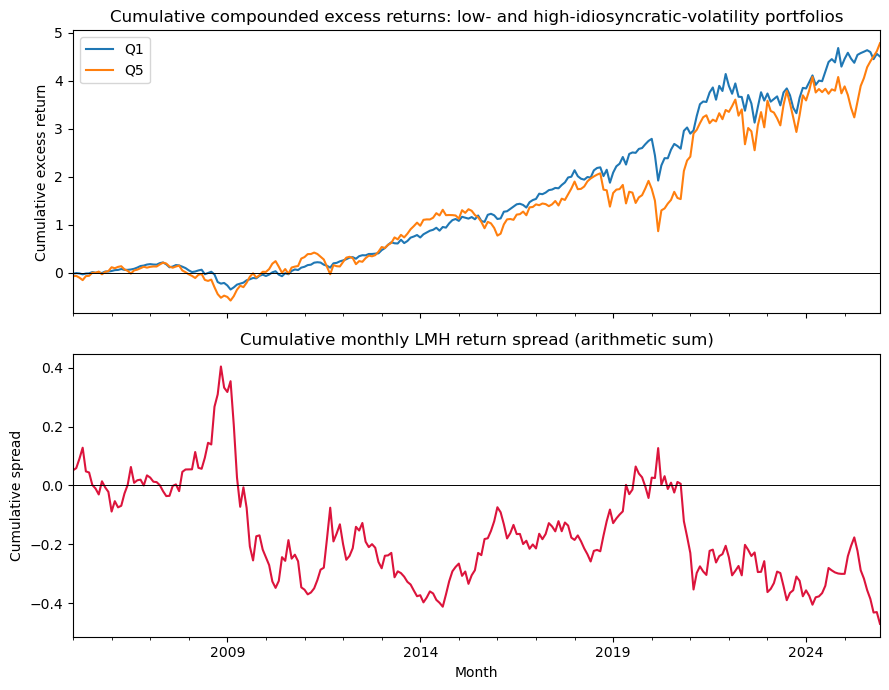

Saved report figure to lmh_cumulative_performance.png.
Audience implication: the current evidence does not establish an LMH premium that can be relied on after trading costs.


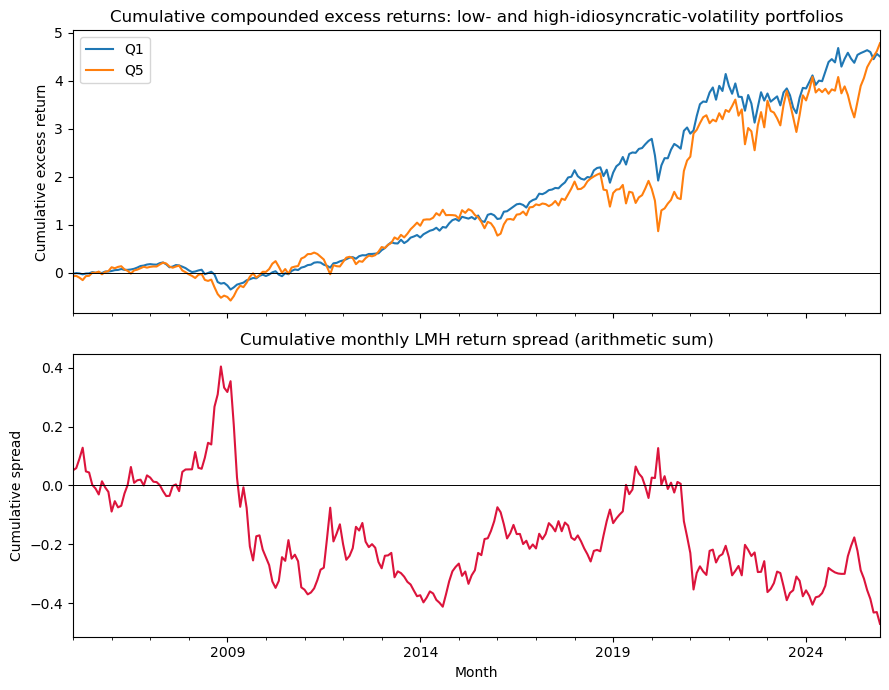

In [58]:
def winsorize_monthly_cross_section(panel, lower=WINSOR_LOWER, upper=WINSOR_UPPER):
    lower_cutoff = panel.quantile(lower, axis=1)
    upper_cutoff = panel.quantile(upper, axis=1)
    return panel.clip(lower=lower_cutoff, upper=upper_cutoff, axis=0)


winsorized_stock_excess = winsorize_monthly_cross_section(stock_excess)
winsorized_idio_vol = winsorize_monthly_cross_section(idio_vol_est)
returns_changed = int((stock_excess.sub(winsorized_stock_excess).abs() > 1e-12).to_numpy().sum())
characteristics_changed = int((idio_vol_est.sub(winsorized_idio_vol).abs() > 1e-12).to_numpy().sum())

winsorized_lag_vol = winsorized_idio_vol.shift(1)
winsorized_n_ranked = winsorized_lag_vol.notna().sum(axis=1)
winsorized_rank = winsorized_lag_vol.rank(axis=1, method="first")
winsorized_quintile = (
    winsorized_rank.mul(N_QUINTILES).floordiv(winsorized_n_ranked, axis=0) + 1
)
winsorized_quintile = winsorized_quintile.where(
    winsorized_n_ranked.ge(N_QUINTILES * MIN_STOCKS_PER_QUINTILE), np.nan
)
winsorized_quintile.loc[~winsorized_quintile.index.isin(sample_months)] = np.nan

winsorized_portfolio_returns = pd.DataFrame({
    f"Q{q}": winsorized_stock_excess.where(winsorized_quintile.eq(q)).mean(axis=1)
    for q in range(1, N_QUINTILES + 1)
}).dropna(how="any")
winsorized_portfolio_returns["LMH"] = (
    winsorized_portfolio_returns["Q1"] - winsorized_portfolio_returns[f"Q{N_QUINTILES}"]
)
winsorized_market = market_excess.reindex(winsorized_portfolio_returns.index)
winsorized_lmh = winsorized_portfolio_returns["LMH"]
winsorized_coefficients, winsorized_errors, winsorized_r_squared, winsorized_n = capm_regression(
    winsorized_lmh, winsorized_market
)
winsorized_alpha_t = winsorized_coefficients[0] / winsorized_errors[0]
winsorized_alpha_p = math.erfc(abs(winsorized_alpha_t) / math.sqrt(2))
raw_lmh_alpha = vol_capm.loc[
    vol_capm["portfolio"].eq("LMH") & vol_capm["term"].eq("alpha")
].iloc[0]

mkt_only_fmb_rows = []
raw_stock_values = stock_excess.reindex(index=fmb_calendar, columns=stock_ids).to_numpy(dtype=float)
mkt_factor_values = fmb_factors["MKT"].to_numpy(dtype=float)
for target_position in range(FACTOR_WINDOW_MONTHS, len(fmb_calendar)):
    historical_returns = raw_stock_values[target_position - FACTOR_WINDOW_MONTHS:target_position]
    historical_market = mkt_factor_values[target_position - FACTOR_WINDOW_MONTHS:target_position]
    first_pass_design = np.column_stack([np.ones(FACTOR_WINDOW_MONTHS), historical_market])
    valid_history = np.isfinite(historical_returns)
    safe_returns = np.where(valid_history, historical_returns, 0.0)
    valid_weights = valid_history.astype(float)
    gram = np.einsum("ti,tj,tn->nij", first_pass_design, first_pass_design, valid_weights, optimize=True)
    rhs = np.einsum("ti,tn->ni", first_pass_design, safe_returns, optimize=True)
    eligible = valid_history.sum(axis=0) >= FACTOR_MIN_OBSERVATIONS
    full_rank = np.zeros(len(stock_ids), dtype=bool)
    candidates = np.flatnonzero(eligible)
    if len(candidates):
        full_rank[candidates] = np.linalg.matrix_rank(gram[candidates]) == first_pass_design.shape[1]
    coefficients = np.full((len(stock_ids), 2), np.nan)
    valid_indices = np.flatnonzero(full_rank)
    if len(valid_indices):
        coefficients[valid_indices] = np.linalg.solve(
            gram[valid_indices], rhs[valid_indices, :, None]
        )[..., 0]
    next_returns = raw_stock_values[target_position]
    cross_section = full_rank & np.isfinite(next_returns)
    y = next_returns[cross_section]
    beta_mkt = coefficients[cross_section, 1]
    if len(y) < 4:
        continue
    design = np.column_stack([np.ones(len(y)), beta_mkt])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue
    gamma, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ gamma
    total_ss = np.sum((y - y.mean()) ** 2)
    r_squared = 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan
    adjusted_r_squared = 1 - (1 - r_squared) * (len(y) - 1) / (len(y) - 2)
    mkt_only_fmb_rows.append({
        "return_month": fmb_calendar[target_position], "gamma_mkt": gamma[1],
        "n_stocks": len(y), "r_squared": r_squared,
        "adjusted_r_squared": adjusted_r_squared,
    })

mkt_only_fmb_monthly = pd.DataFrame(mkt_only_fmb_rows).set_index("return_month").sort_index()
if mkt_only_fmb_monthly.empty:
    raise ValueError("No MKT-only Fama-MacBeth cross-sections were estimable.")
mkt_only_prices = mkt_only_fmb_monthly["gamma_mkt"].to_numpy(dtype=float)
mkt_only_mean = mkt_only_prices.mean()
mkt_only_hac_variance = newey_west_variance(
    (mkt_only_prices - mkt_only_mean).reshape(-1, 1), lags=HAC_LAGS
)[0, 0]
mkt_only_se = np.sqrt(max(mkt_only_hac_variance, 0) / len(mkt_only_prices) ** 2)
mkt_only_t = mkt_only_mean / mkt_only_se
mkt_only_p = math.erfc(abs(mkt_only_t) / math.sqrt(2))
mkt_only_fmb_summary = pd.DataFrame([{
    "model": "MKT only", "mean_monthly_MKT_premium": mkt_only_mean,
    "hac_std_error": mkt_only_se, "t_stat": mkt_only_t, "p_value": mkt_only_p,
    "average_cross_sectional_R2": mkt_only_fmb_monthly["r_squared"].mean(),
    "average_adjusted_cross_sectional_R2": mkt_only_fmb_monthly["adjusted_r_squared"].mean(),
    "n_months": len(mkt_only_prices),
    "average_stocks_per_month": mkt_only_fmb_monthly["n_stocks"].mean(),
}])

fmb_summary["average_cross_sectional_R2"] = fmb_monthly_prices["cross_section_r_squared"].mean()
fmb_summary["average_adjusted_cross_sectional_R2"] = (
    1 - (1 - fmb_monthly_prices["cross_section_r_squared"])
    * (fmb_monthly_prices["n_stocks"] - 1) / (fmb_monthly_prices["n_stocks"] - 3)
).mean()
fmb_lmh_only_summary["average_cross_sectional_R2"] = fmb_lmh_only_monthly_prices["cross_section_r_squared"].mean()
fmb_lmh_only_summary["average_adjusted_cross_sectional_R2"] = (
    1 - (1 - fmb_lmh_only_monthly_prices["cross_section_r_squared"])
    * (fmb_lmh_only_monthly_prices["n_stocks"] - 1) / (fmb_lmh_only_monthly_prices["n_stocks"] - 2)
).mean()
winsorized_fmb_rows = []
for return_month, beta_rows in fmb_first_pass_betas.groupby("return_month", sort=True):
    if return_month not in winsorized_stock_excess.index:
        continue
    y = winsorized_stock_excess.loc[return_month].reindex(beta_rows["permno"]).to_numpy(dtype=float)
    beta_values = beta_rows[["beta_mkt", "beta_lmh"]].to_numpy(dtype=float)
    valid_cross_section = np.isfinite(y) & np.isfinite(beta_values).all(axis=1)
    y = y[valid_cross_section]
    beta_values = beta_values[valid_cross_section]
    if len(y) < 4:
        continue
    design = np.column_stack([np.ones(len(y)), beta_values])
    if np.linalg.matrix_rank(design) < design.shape[1]:
        continue
    gamma, _, _, _ = np.linalg.lstsq(design, y, rcond=None)
    residuals = y - design @ gamma
    total_ss = np.sum((y - y.mean()) ** 2)
    winsorized_fmb_rows.append({
        "return_month": return_month,
        "gamma_lmh": gamma[2],
        "n_stocks": len(y),
        "r_squared": 1 - residuals @ residuals / total_ss if total_ss > 0 else np.nan,
    })

winsorized_fmb_monthly = pd.DataFrame(winsorized_fmb_rows).set_index("return_month").sort_index()
if winsorized_fmb_monthly.empty:
    raise ValueError("No winsorized Fama-MacBeth cross-sections were estimable.")
winsorized_prices = winsorized_fmb_monthly["gamma_lmh"].to_numpy(dtype=float)
winsorized_mean_price = winsorized_prices.mean()
winsorized_hac_variance = newey_west_variance(
    (winsorized_prices - winsorized_mean_price).reshape(-1, 1), lags=HAC_LAGS
)[0, 0]
winsorized_price_se = np.sqrt(max(winsorized_hac_variance, 0) / len(winsorized_prices) ** 2)
winsorized_price_t = winsorized_mean_price / winsorized_price_se
winsorized_price_p = math.erfc(abs(winsorized_price_t) / math.sqrt(2))

winsorized_fmb_summary = pd.DataFrame([{
    "test": "Winsorized returns (MKT + LMH)",
    "mean_monthly_LMH_premium": winsorized_mean_price,
    "hac_std_error": winsorized_price_se,
    "t_stat": winsorized_price_t,
    "p_value": winsorized_price_p,
    "avg_cross_sectional_R2": winsorized_fmb_monthly["r_squared"].mean(),
    "avg_adjusted_cross_sectional_R2": (
        1 - (1 - winsorized_fmb_monthly["r_squared"])
        * (winsorized_fmb_monthly["n_stocks"] - 1) / (winsorized_fmb_monthly["n_stocks"] - 3)
    ).mean(),
    "n_months": len(winsorized_prices),
    "average_stocks_per_month": winsorized_fmb_monthly["n_stocks"].mean(),
}])

print("Fama-MacBeth factor-pricing benchmark and average fit:")
print("MKT-only model, estimated independently in both passes:")
display(mkt_only_fmb_summary)
print("Average cross-sectional R-squared comparison (adjusted for model size):")
display(pd.DataFrame([
    {"model": "MKT only", "average_R2": mkt_only_fmb_monthly["r_squared"].mean(),
     "average_adjusted_R2": mkt_only_fmb_monthly["adjusted_r_squared"].mean()},
    {"model": "LMH only", "average_R2": fmb_lmh_only_summary["average_cross_sectional_R2"].iloc[0],
     "average_adjusted_R2": fmb_lmh_only_summary["average_adjusted_cross_sectional_R2"].iloc[0]},
    {"model": "MKT + LMH", "average_R2": fmb_summary["average_cross_sectional_R2"].iloc[0],
     "average_adjusted_R2": fmb_summary["average_adjusted_cross_sectional_R2"].iloc[0]},
]))
print("Monthly 1st/99th percentile winsorization counts:")
display(pd.DataFrame([
    {"series": "Stock excess returns", "values_changed": returns_changed},
    {"series": "Idiosyncratic-volatility sorting characteristic", "values_changed": characteristics_changed},
]))
print("LMH CAPM alpha: raw versus winsorized stock returns and sorting characteristic:")
display(pd.DataFrame([
    {"sample": "Raw baseline", "alpha": raw_lmh_alpha["estimate"],
     "hac_std_error": raw_lmh_alpha["hac_std_error"], "p_value": raw_lmh_alpha["p_value_normal_approx"],
     "R2": raw_lmh_alpha["r_squared"], "n_months": raw_lmh_alpha["n_months"]},
    {"sample": "Winsorized returns and characteristic", "alpha": winsorized_coefficients[0],
     "hac_std_error": winsorized_errors[0], "p_value": winsorized_alpha_p,
     "R2": winsorized_r_squared, "n_months": winsorized_n},
]))
print("Winsorized Fama-MacBeth sensitivity (dependent returns clipped; first-pass betas held fixed):")
display(winsorized_fmb_summary)

raw_joint_lmh = raw_full_sample_fmb_summary.loc[
    raw_full_sample_fmb_summary["model"].eq("MKT + LMH")
    & raw_full_sample_fmb_summary["term"].eq("LMH beta")
].iloc[0]
crisis_joint_lmh = crisis_fmb_summary.loc[
    crisis_fmb_summary["model"].eq("MKT + LMH")
    & crisis_fmb_summary["term"].eq("LMH beta")
].iloc[0]
print("Fama-MacBeth sensitivity comparison for the joint-model LMH premium:")
display(pd.DataFrame([
    {"test": "Full sample, raw returns", "premium": raw_joint_lmh["mean_monthly_risk_premium"],
     "p_value": raw_joint_lmh["p_value"], "months": raw_joint_lmh["n_months"]},
    {"test": "Full sample, winsorized dependent returns", "premium": winsorized_mean_price,
     "p_value": winsorized_price_p, "months": len(winsorized_prices)},
    {"test": "Crisis months, raw returns", "premium": crisis_joint_lmh["mean_monthly_risk_premium"],
     "p_value": crisis_joint_lmh["p_value"], "months": crisis_joint_lmh["n_months"]},
]))
print("The earlier full-sample raw-return run uses the same non-winsorized baseline; it is a consistency rerun, not a comparison to a winsorized baseline.")

state_returns = pd.DataFrame({"LMH": quintile_returns["LMH"], "MKT": mkt_excess}).dropna()
crisis_indicator = (
    ((state_returns.index >= pd.Timestamp("2007-12-31"))
     & (state_returns.index <= pd.Timestamp("2009-06-30")))
    | ((state_returns.index >= pd.Timestamp("2020-02-29"))
       & (state_returns.index <= pd.Timestamp("2020-04-30")))
)
state_summary_rows = []
for label, mask in [
    ("Down market (MKT < 0)", state_returns["MKT"].lt(0)),
    ("Up market (MKT >= 0)", state_returns["MKT"].ge(0)),
    ("Recession/COVID windows", pd.Series(crisis_indicator, index=state_returns.index)),
    ("Other months", ~pd.Series(crisis_indicator, index=state_returns.index)),
]:
    sample = state_returns.loc[mask, "LMH"]
    state_summary_rows.append({"state": label, "months": len(sample), "mean_LMH_return": sample.mean(),
                               "std_LMH_return": sample.std(ddof=1)})
state_summary = pd.DataFrame(state_summary_rows)

state_difference_rows = []
for label, indicator in [
    ("Down market minus up market", state_returns["MKT"].lt(0).to_numpy(dtype=float)),
    ("Recession/COVID minus other months", crisis_indicator.astype(float)),
]:
    coefficients, standard_errors, _, _ = ols_hac(state_returns["LMH"], indicator)
    difference, standard_error = coefficients[1], standard_errors[1]
    t_stat = difference / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    state_difference_rows.append({"comparison": label, "mean_difference": difference,
                                  "hac_std_error": standard_error, "t_stat": t_stat,
                                  "p_value": p_value})
state_differences = pd.DataFrame(state_difference_rows)
print("LMH returns by market/recession state (descriptive monthly returns):")
display(state_summary)
print(f"State differences use Newey-West/HAC standard errors ({HAC_LAGS} lags) on the continuous monthly series.")
display(state_differences)
print("Largest LMH monthly returns (context for outlier influence):")
display(pd.concat([
    state_returns["LMH"].nsmallest(5).rename("LMH_return").rename_axis("date").reset_index().assign(extreme="lowest"),
    state_returns["LMH"].nlargest(5).rename("LMH_return").rename_axis("date").reset_index().assign(extreme="highest"),
], ignore_index=True))

if winsorized_alpha_p < 0.05 and raw_lmh_alpha["p_value_normal_approx"] >= 0.05:
    print("Portfolio CAPM sensitivity: the LMH alpha is significant only after 1st/99th winsorization; the raw alpha is not. Treat this as sensitivity to outlier handling, not a robust premium.")
elif winsorized_alpha_p >= 0.05 and raw_lmh_alpha["p_value_normal_approx"] >= 0.05:
    print("Portfolio CAPM sensitivity: neither the raw nor winsorized LMH alpha is significant at 5%.")
else:
    print("Portfolio CAPM sensitivity: the raw and winsorized LMH alpha tests differ; compare their signs, sizes, and confidence intervals.")

if not bool(raw_joint_lmh["significant_5pct"]) and not bool(crisis_joint_lmh["significant_5pct"]) and winsorized_price_p >= 0.05:
    print("Conclusion: the joint-model LMH premium is not statistically distinguishable from zero in the raw, winsorized, or crisis-only tests. This is consistent with weak-form efficiency, but does not prove efficiency or distinguish behavioral from risk-based explanations.")
else:
    print("Conclusion: at least one sensitivity specification produces a statistically significant LMH premium; interpret it alongside its sign, economic size, sample length, and the state-dependence results rather than treating significance alone as proof of mispricing.")
fig, (wealth_ax, spread_ax) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
((1 + quintile_returns[["Q1", f"Q{N_QUINTILES}"]]).cumprod() - 1).plot(ax=wealth_ax)
wealth_ax.set_title("Cumulative compounded excess returns: low- and high-idiosyncratic-volatility portfolios")
wealth_ax.set_ylabel("Cumulative excess return")
wealth_ax.axhline(0, color="black", linewidth=0.7)
quintile_returns["LMH"].cumsum().plot(ax=spread_ax, color="crimson")
spread_ax.set_title("Cumulative monthly LMH return spread (arithmetic sum)")
spread_ax.set_ylabel("Cumulative spread")
spread_ax.set_xlabel("Month")
spread_ax.axhline(0, color="black", linewidth=0.7)
fig.tight_layout()
figure_path = data_dir / "lmh_cumulative_performance.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
display(fig)
print(f"Saved report figure to {figure_path.name}.")
print("Audience implication: the current evidence does not establish an LMH premium that can be relied on after trading costs.")

## Market risk-price robustness checks (not p-value tuning)

A high p-value for the Fama-MacBeth market coefficient means the estimated **cross-sectional price of market-beta exposure** is imprecise; it does not mean individual stocks have insignificant market betas. This section reports the market risk-price estimate under pre-declared model and inference alternatives: the 60-month MKT-only and MKT + LMH models, the 36-month alternative beta window (with at least 24 valid months), and Newey-West lag choices of 0, 3, 6, and 12 for the same 60-month monthly-slope series. Every specification is shown; none is selected because it produces a preferred p-value.

For context, the mean realized market excess return over the same second-pass months is tested separately. That is a time-series market premium, not the Fama-MacBeth cross-sectional price of beta. A significant realized market mean cannot be presented as proof that the Fama-MacBeth market-beta price is significant.

In [59]:
def summarize_monthly_price(prices, lags, term, model, beta_window):
    values = np.asarray(prices, dtype=float)
    estimate = values.mean()
    scores = (values - estimate).reshape(-1, 1)
    variance = newey_west_variance(scores, lags=lags)[0, 0]
    standard_error = np.sqrt(max(variance, 0) / len(values) ** 2)
    t_stat = estimate / standard_error if standard_error > 0 else np.nan
    p_value = math.erfc(abs(t_stat) / math.sqrt(2)) if np.isfinite(t_stat) else np.nan
    return {
        "model": model,
        "beta_window_months": beta_window,
        "HAC_lags": lags,
        "risk_price_per_month": estimate,
        "HAC_standard_error": standard_error,
        "t_stat": t_stat,
        "p_value_normal_approx": p_value,
        "n_months": len(values),
    }


market_price_robustness_rows = []
for model_name, monthly_table in [
    ("MKT only, 60-month betas", mkt_only_fmb_monthly),
    ("MKT + LMH, 60-month betas", fmb_monthly_prices),
]:
    market_column = "gamma_mkt"
    for lag_count in [0, 3, 6, 12]:
        market_price_robustness_rows.append(
            summarize_monthly_price(
                monthly_table[market_column], lag_count, "MKT", model_name, 60
            )
        )


def estimate_fmb_with_window(window_months, min_observations, include_lmh):
    factor_columns = ["MKT", "LMH"] if include_lmh else ["MKT"]
    factor_values = fmb_factors[factor_columns].to_numpy(dtype=float)
    stock_values = stock_return_values
    monthly_rows = []
    for target_position in range(window_months, len(fmb_calendar)):
        history_returns = stock_values[target_position - window_months:target_position]
        history_factors = factor_values[target_position - window_months:target_position]
        design_first = np.column_stack([np.ones(window_months), history_factors])
        valid_history = np.isfinite(history_returns)
        counts = valid_history.sum(axis=0)
        safe_returns = np.where(valid_history, history_returns, 0.0)
        weights = valid_history.astype(float)
        gram = np.einsum("ti,tj,tn->nij", design_first, design_first, weights, optimize=True)
        rhs = np.einsum("ti,tn->ni", design_first, safe_returns, optimize=True)
        eligible = counts >= min_observations
        full_rank = np.zeros(len(stock_ids), dtype=bool)
        candidates = np.flatnonzero(eligible)
        if len(candidates):
            full_rank[candidates] = (
                np.linalg.matrix_rank(gram[candidates]) == design_first.shape[1]
            )
        beta_coefficients = np.full((len(stock_ids), design_first.shape[1]), np.nan)
        valid_indices = np.flatnonzero(full_rank)
        if len(valid_indices):
            beta_coefficients[valid_indices] = np.linalg.solve(
                gram[valid_indices], rhs[valid_indices, :, None]
            )[..., 0]
        current_returns = stock_values[target_position]
        cross_section = full_rank & np.isfinite(current_returns)
        if cross_section.sum() < design_first.shape[1] + 1:
            continue
        y = current_returns[cross_section]
        design_second = np.column_stack([
            np.ones(len(y)), beta_coefficients[cross_section, 1:]
        ])
        if np.linalg.matrix_rank(design_second) < design_second.shape[1]:
            continue
        prices, _, _, _ = np.linalg.lstsq(design_second, y, rcond=None)
        monthly_rows.append({
            "return_month": fmb_calendar[target_position],
            "gamma_mkt": prices[1],
            "n_stocks": len(y),
        })
    monthly_prices = pd.DataFrame(monthly_rows).set_index("return_month").sort_index()
    if monthly_prices.empty:
        raise ValueError(f"No Fama-MacBeth months estimated for a {window_months}-month window.")
    return monthly_prices


short_window_joint = estimate_fmb_with_window(36, 24, include_lmh=True)
short_window_mkt_only = estimate_fmb_with_window(36, 24, include_lmh=False)
for model_name, monthly_table in [
    ("MKT only, 36-month betas (min 24 obs)", short_window_mkt_only),
    ("MKT + LMH, 36-month betas (min 24 obs)", short_window_joint),
]:
    market_price_robustness_rows.append(
        summarize_monthly_price(
            monthly_table["gamma_mkt"], 6, "MKT", model_name, 36
        )
    )

market_price_robustness = pd.DataFrame(market_price_robustness_rows)
market_price_robustness["risk_price_percent_per_month"] = (
    market_price_robustness["risk_price_per_month"] * 100
)
market_sample_returns = fmb_factors.loc[fmb_monthly_prices.index, "MKT"].to_numpy(dtype=float)
market_mean_reference = summarize_monthly_price(
    market_sample_returns, HAC_LAGS, "Realized market excess return",
    "Time-series mean (not Fama-MacBeth)", 0
)
market_mean_reference["risk_price_percent_per_month"] = (
    market_mean_reference["risk_price_per_month"] * 100
)
print("Market risk-price estimates across models and HAC lag choices (all specifications shown):")
display(market_price_robustness[[
    "model", "HAC_lags", "risk_price_percent_per_month", "HAC_standard_error",
    "t_stat", "p_value_normal_approx", "n_months",
]])
print("Separate reference: realized market excess-return mean over the same 60-month Fama-MacBeth sample:")
display(pd.DataFrame([market_mean_reference]))
print(
    "Interpretation: the realized market excess-return mean is a time-series average; "
    "the Fama-MacBeth MKT coefficient is a cross-sectional price of estimated market-beta exposure. "
    "They are related under a correctly specified CAPM but are not the same estimate or hypothesis test."
)
print(
    "Do not select a window, model, or HAC lag because it gives the smallest p-value. "
    "Report the pre-specified baseline and the full sensitivity table; the 36-month model "
    "also changes the beta-estimation minimum-observation rule."
)

Market risk-price estimates across models and HAC lag choices (all specifications shown):


,model,HAC_lags,risk_price_percent_per_month,HAC_standard_error,t_stat,p_value_normal_approx,n_months
0,"MKT only, 60-month betas",0,0.242835,0.003023,0.803270,0.421819,192
1,"MKT only, 60-month betas",3,0.242835,0.002754,0.881719,0.377929,192
2,"MKT only, 60-month betas",6,0.242835,0.002605,0.932359,0.351151,192
3,"MKT only, 60-month betas",12,0.242835,0.002572,0.944096,0.345121,192
4,"MKT + LMH, 60-month betas",0,0.286309,0.002636,1.086046,0.277458,192
5,"MKT + LMH, 60-month betas",3,0.286309,0.002505,1.143061,0.253013,192
6,"MKT + LMH, 60-month betas",6,0.286309,0.002535,1.129455,0.258706,192
7,"MKT + LMH, 60-month betas",12,0.286309,0.002571,1.113759,0.265383,192
8,"MKT only, 36-month betas (min 24 obs)",6,0.429093,0.002755,1.557352,0.119387,216
9,"MKT + LMH, 36-month betas (min 24 obs)",6,0.450105,0.002704,1.664842,0.095944,216


Separate reference: realized market excess-return mean over the same 60-month Fama-MacBeth sample:


,model,beta_window_months,HAC_lags,risk_price_per_month,HAC_standard_error,t_stat,p_value_normal_approx,n_months,risk_price_percent_per_month
0,Time-series mean (not Fama-MacBeth),0,6,0.010842,0.002444,4.436189,0.000009,192,1.084219


Interpretation: the realized market excess-return mean is a time-series average; the Fama-MacBeth MKT coefficient is a cross-sectional price of estimated market-beta exposure. They are related under a correctly specified CAPM but are not the same estimate or hypothesis test.
Do not select a window, model, or HAC lag because it gives the smallest p-value. Report the pre-specified baseline and the full sensitivity table; the 36-month model also changes the beta-estimation minimum-observation rule.
